# Análise Exploratória de Dados: Cancelamento de Clientes de Cartão de Crédito
**Módulo:** Técnicas de Programação I (Python)  
**Aluno:** Sérgio Ricardo dos Santos  
**Data:** 24/11/2026

## 1. Apresentação da Base e Perguntas de Negócio

### 1.1 Origem dos Dados
A base de dados utilizada é a **Credit Card Customers** (arquivo BankChurners.csv).

### 1.3 Perguntas de Negócio (Definidas Antes da Análise)
1. **Perfil Demográfico e Renda:** O cancelamento concentra-se em alguma faixa de renda específica ou categoria de cartão?
2. **Engajamento e Produtos:** Clientes com menos produtos contratados apresentam maior taxa de cancelamento?
3. **Sinais de Alerta (Inatividade e Contato):** Existe relação entre o número de meses inativos ou contatos com o atendimento e o encerramento da conta?
4. **Comportamento Transacional:** Qual a diferença no volume financeiro  e na frequência de uso entre clientes ativos e clientes que cancelaram?
5. **Uso do Limite:** Clientes que cancelam possuem menor taxa de utilização do limite ou limites mais baixos?

In [27]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Baixando e carregando a base
path = kagglehub.dataset_download("sakshigoyal7/credit-card-customers")
df = pd.read_csv(path + "/BankChurners.csv")

# Vendo as 5 primeiras linhas
df.head()

Using Colab cache for faster access to the 'credit-card-customers' dataset.


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [28]:
# Exibindo as 5 primeiras linhas
display(df_limpo.head())

# Exibindo as 5 últimas linhas
display(df_limpo.tail())

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,...,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Status
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,...,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,Ativo
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,...,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,Ativo
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,...,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,Ativo
3,Existing Customer,40,F,4,High School,Não Informado,Less than $40K,Blue,34,3,...,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,Ativo
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,...,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,Ativo


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,...,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Status
10122,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,3,...,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462,Ativo
10123,Attrited Customer,41,M,2,Não Informado,Divorced,$40K - $60K,Blue,25,4,...,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511,Cancelado
10124,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,5,...,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000,Cancelado
10125,Attrited Customer,30,M,2,Graduate,Não Informado,$40K - $60K,Blue,36,4,...,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000,Cancelado
10126,Attrited Customer,43,F,2,Graduate,Married,Less than $40K,Silver,25,6,...,4,10388.0,1961,8427.0,0.703,10294,61,0.649,0.189,Cancelado


In [29]:
print("Tamanho da tabela (linhas, colunas):", df.shape)
df.info()

Tamanho da tabela (linhas, colunas): (10127, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                          

In [30]:
print("Valores nulos (NaN) por coluna:")
print(df.isnull().sum())

print("\nLinhas duplicadas:", df.duplicated().sum())

Valores nulos (NaN) por coluna:
CLIENTNUM                                                                                                                             0
Attrition_Flag                                                                                                                        0
Customer_Age                                                                                                                          0
Gender                                                                                                                                0
Dependent_count                                                                                                                       0
Education_Level                                                                                                                       0
Marital_Status                                                                                                                        0
Income_Category 

In [31]:
# Olhando as categorias para ver se tem 'Unknown' ou erros de escrita
print(df["Education_Level"].value_counts())
print("\n", df["Marital_Status"].value_counts())
print("\n", df["Income_Category"].value_counts())
print("\n", df["Card_Category"].value_counts())

Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64

 Marital_Status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64

 Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64

 Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64


In [32]:
# Resumo estatístico para ver mínimos e máximos (checar valores impossíveis)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CLIENTNUM,10127.0,7.391776e+08,3.690378e+07,7.080821e+08,7.130368e+08,7.179264e+08,7.731435e+08,8.283431e+08
Customer_Age,10127.0,4.632596e+01,8.016814e+00,2.600000e+01,4.100000e+01,4.600000e+01,5.200000e+01,7.300000e+01
Dependent_count,10127.0,2.346203e+00,1.298908e+00,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00
Months_on_book,10127.0,3.592841e+01,7.986416e+00,1.300000e+01,3.100000e+01,3.600000e+01,4.000000e+01,5.600000e+01
Total_Relationship_Count,10127.0,3.812580e+00,1.554408e+00,1.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00
Months_Inactive_12_mon,10127.0,2.341167e+00,1.010622e+00,0.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00,6.000000e+00
Contacts_Count_12_mon,10127.0,2.455317e+00,1.106225e+00,0.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00,6.000000e+00
Credit_Limit,10127.0,8.631954e+03,9.088777e+03,1.438300e+03,2.555000e+03,4.549000e+03,1.106750e+04,3.451600e+04
Total_Revolving_Bal,10127.0,1.162814e+03,8.149873e+02,0.000000e+00,3.590000e+02,1.276000e+03,1.784000e+03,2.517000e+03
Avg_Open_To_Buy,10127.0,7.469140e+03,9.090685e+03,3.000000e+00,1.324500e+03,3.474000e+03,9.859000e+03,3.451600e+04


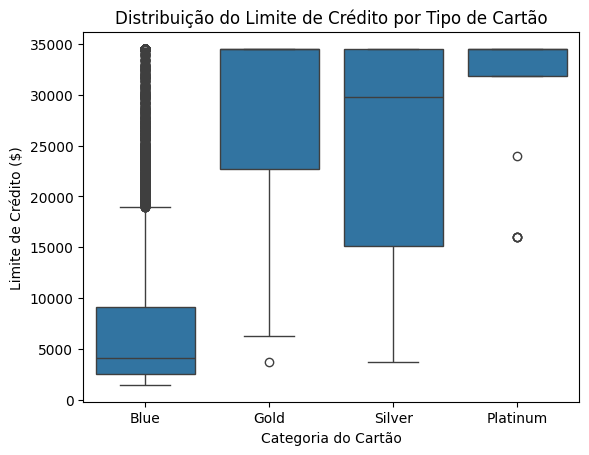

In [33]:
# Verificando outliers de Limite de Crédito divididos por Categoria de Cartão
sns.boxplot(data=df, x="Card_Category", y="Credit_Limit")
plt.title("Distribuição do Limite de Crédito por Tipo de Cartão")
plt.xlabel("Categoria do Cartão")
plt.ylabel("Limite de Crédito ($)")
plt.show()

Observamos que cada categoria de cartão possui uma faixa de limite esperada. Os pontos acima das hastes representam clientes com limites atípicos dentro daquela categoria, e não serão apagados pois representam, provavelmente, clientes reais de alta renda.

Decisões de Limpeza:

**Remoção de colunas desnecessárias:** As duas últimas colunas (Naive_Bayes...) são resultados de um modelo pronto que veio no arquivo original e não fazem parte dos dados do negócio, por isso serão removidas. A coluna CLIENTNUM também será removida por ser apenas um número de cadastro.

**Tratamento de valores "Unknown":** Nas colunas de escolaridade, estado civil e renda, existem registros preenchidos como "Unknown" (Desconhecido). Optamos por mantê-los como uma categoria própria (renomeando para "Não Informado"), pois apagar essas linhas faria perder mais de 15% da base e informações importantes de transações.

**Tradução da variável alvo:** Vamos criar uma coluna Status traduzida (Ativo e Cancelado) para facilitar a leitura dos gráficos pela área de negócio.

In [34]:
# 1. Apagando as 2 últimas colunas e o ID do cliente
df_limpo = df.drop(columns=[
    "CLIENTNUM",
    "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1",
    "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2"
])

# 2. Substituindo 'Unknown' por 'Não Informado'
df_limpo = df_limpo.replace("Unknown", "Não Informado")

# 3. Traduzindo o status do cliente para português
df_limpo["Status"] = df_limpo["Attrition_Flag"].replace({
    "Existing Customer": "Ativo",
    "Attrited Customer": "Cancelado"
})

print("Novo tamanho da base limpa:", df_limpo.shape)

Novo tamanho da base limpa: (10127, 21)


Status           Ativo  Cancelado
Income_Category                  
$120K +           82.7       17.3
$40K - $60K       84.9       15.1
$60K - $80K       86.5       13.5
$80K - $120K      84.2       15.8
Less than $40K    82.8       17.2
Não Informado     83.2       16.8


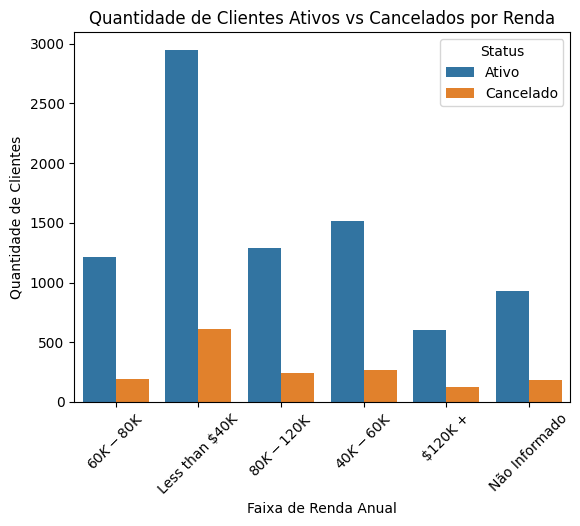

In [35]:
# Pergunta 1: Qual a taxa geral de cancelamento e como ela se divide por faixa de renda?
tabela_renda = pd.crosstab(df_limpo["Income_Category"], df_limpo["Status"], normalize="index") * 100
print(tabela_renda.round(1))

# Gráfico
sns.countplot(data=df_limpo, x="Income_Category", hue="Status")
plt.title("Quantidade de Clientes Ativos vs Cancelados por Renda")
plt.xlabel("Faixa de Renda Anual")
plt.ylabel("Quantidade de Clientes")
plt.xticks(rotation=45)
plt.show()

O gráfico mostra que a maioria dos clientes está na faixa abaixo de $40K, e a taxa de cancelamento fica em torno de **13,5% a 17,3%** em quase todas as faixas, mostrando que a renda sozinha não define o cancelamento

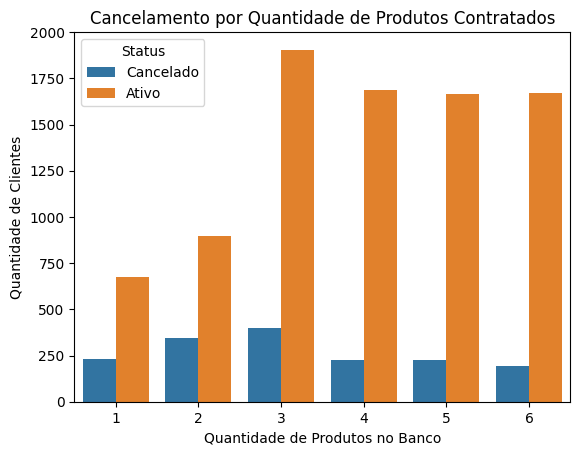

In [36]:
# Pergunta 2: Clientes com menos produtos no banco cancelam mais?
sns.countplot(data=df_limpo, x="Total_Relationship_Count", hue="Status")
plt.title("Cancelamento por Quantidade de Produtos Contratados")
plt.xlabel("Quantidade de Produtos no Banco")
plt.ylabel("Quantidade de Clientes")
plt.show()

Clientes que possuem apenas **1 ou 2 produtos** com o banco têm uma proporção bem maior de cancelamento em comparação com quem possui 4 ou mais produtos.

           Months_Inactive_12_mon  Contacts_Count_12_mon
Status                                                  
Ativo                        2.27                   2.36
Cancelado                    2.69                   2.97


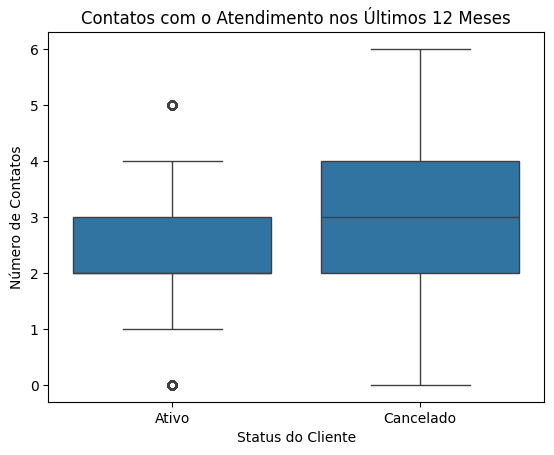

In [37]:
# Pergunta 3: Clientes que cancelam ficam mais meses inativos ou ligam mais para o banco?
print(df_limpo.groupby("Status")[["Months_Inactive_12_mon", "Contacts_Count_12_mon"]].mean().round(2))

sns.boxplot(data=df_limpo, x="Status", y="Contacts_Count_12_mon")
plt.title("Contatos com o Atendimento nos Últimos 12 Meses")
plt.xlabel("Status do Cliente")
plt.ylabel("Número de Contatos")
plt.show()

Quem cancela entra em contato com o banco em média **2,97 vezes ao ano**, contra **2,36 vezes dos clientes ativos** — inclusive todos os clientes que ligaram 6 vezes acabaram cancelando."

           Total_Trans_Amt  Total_Trans_Ct
Status                                    
Ativo               4100.0            71.0
Cancelado           2329.0            43.0


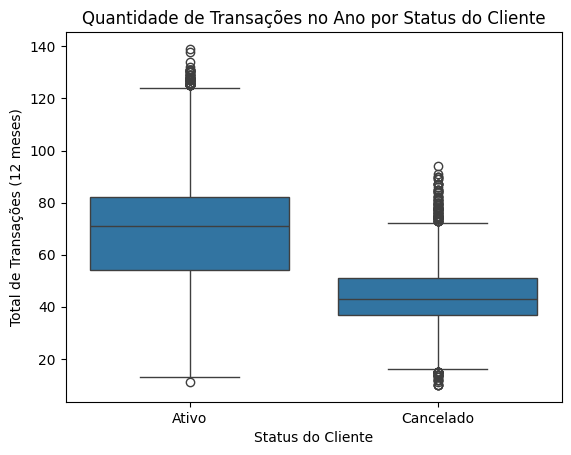

In [38]:
# Pergunta 4: Existe diferença na quantidade e no valor das transações?
print(df_limpo.groupby("Status")[["Total_Trans_Amt", "Total_Trans_Ct"]].median())

sns.boxplot(data=df_limpo, x="Status", y="Total_Trans_Ct")
plt.title("Quantidade de Transações no Ano por Status do Cliente")
plt.xlabel("Status do Cliente")
plt.ylabel("Total de Transações (12 meses)")
plt.show()

A diferença é muito clara: clientes ativos fazem uma mediana de **71 transações** no ano, enquanto quem cancela faz apenas **43 transações**.

           Credit_Limit  Avg_Utilization_Ratio
Status                                        
Ativo            4643.5                  0.211
Cancelado        4178.0                  0.000


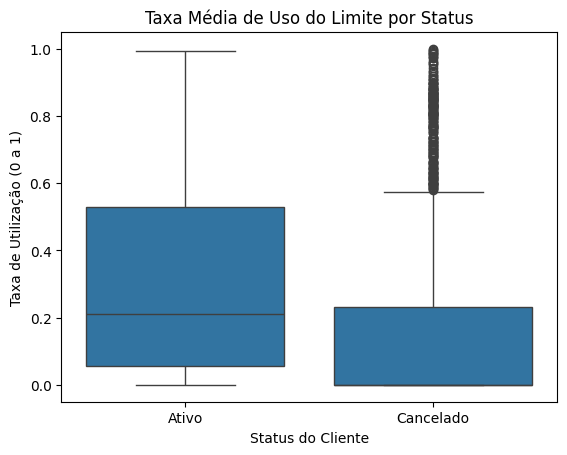

In [39]:
#Pergunta 5: Clientes que cancelam usam menos o limite do cartão?
print(df_limpo.groupby("Status")[["Credit_Limit", "Avg_Utilization_Ratio"]].median())

sns.boxplot(data=df_limpo, x="Status", y="Avg_Utilization_Ratio")
plt.title("Taxa Média de Uso do Limite por Status")
plt.xlabel("Status do Cliente")
plt.ylabel("Taxa de Utilização (0 a 1)")
plt.show()

Clientes que cancelam quase não utilizam o limite disponível (mediana de uso de apenas **0,0, ou seja, cartão parado)**, enquanto clientes ativos mantêm uma mediana de uso de **0,21 (21% do limite)**.

## 5. Conclusões

### Principais Achados
1. **Queda no uso é o maior sinal de cancelamento:** Clientes que cancelam realizam cerca de 40% menos transações no ano (mediana de 43 contra 71 dos ativos) e deixam o limite praticamente sem uso.
2. **Excesso de contatos indica insatisfação:** Clientes cancelados entraram em contato com o banco com mais frequência nos últimos 12 meses. Todos os clientes que atingiram 6 contatos encerraram a conta.
3. **Fidelização por múltiplos produtos funciona:** Clientes com 4 a 6 produtos ativos no banco apresentam taxas de cancelamento muito menores do que clientes que têm apenas o cartão (1 ou 2 produtos).
4. **Renda não é o fator principal:** A proporção de cancelamento é parecida entre todas as faixas salariais, indicando que o problema está mais ligado ao uso do cartão do que ao poder aquisitivo.

### Limitações dos Dados
* Os dados mostram associação entre baixo uso e cancelamento, mas não informam o **motivo real** declarado pelo cliente (ex: anuidade alta, falta de benefícios ou migração para concorrente).
* Cerca de 15% da base não possui informação de escolaridade ou renda (`Não Informado`), o que limita análises demográficas mais profundas desses grupos.